In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from IPython.display import display

# analysis.ipynb is in notebooks/; models are in the project-root models/ folder
model_dir = Path.cwd().parent/"models"

# Same raw data as XGBOOST.ipynb and XGBoost_cluster.ipynb
df = pd.read_csv("../data/df_main_final.csv").drop(columns = "Unnamed: 0")


model_files = {
    "Global XGBoost": "xgb_global.json",
    "RB Cluster": "xgb_rb.json",
    "QB + TE Cluster": "xgb_qb_te.json",
    "WR + K Cluster": "xgb_wr_k.json"
}

loaded_models = {}

for name, filename in model_files.items():
    path = model_dir / filename

    if not path.exists():
        print(f"{name}: FILE NOT FOUND ({path})")
        continue

    model = xgb.XGBRegressor()
    model.load_model(str(path))
    loaded_models[name] = model

    print(f"\n{name}: Loaded successfully")
    print("Features:", model.get_booster().num_features())
    print("Trees:", model.get_booster().num_boosted_rounds())
    print("Feature names:", model.get_booster().feature_names)

print(f"\nLoaded {len(loaded_models)} of 4 models.")

/tmp/ipykernel_10767/2793920321.py:12: DtypeWarning: Columns (0: season_type) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/df_main_final.csv").drop(columns = "Unnamed: 0")



Global XGBoost: Loaded successfully
Features: 97
Trees: 411
Feature names: ['player', 'position', 'week', 'receptions', 'receivingTargets', 'receivingYards', 'yardsPerReception', 'receivingTouchdowns', 'longReception', 'rushingAttempts', 'rushingYards', 'yardsPerRushAttempt', 'longRushing', 'rushingTouchdowns', 'fumbles', 'fumblesLost', 'fumblesForced', 'kicksBlocked', 'completions', 'passingAttempts', 'passingYards', 'completionPct', 'yardsPerPassAttempt', 'passingTouchdowns', 'interceptions', 'longPassing', 'sacks', 'QBRating', 'adjQBR', 'longFieldGoalMade', 'fieldGoalPct', 'fieldGoalsMadeYardsAverage', 'totalKickingPoints', 'totalTackles', 'soloTackles', 'assistTackles', 'stuffs', 'stuffYards', 'fumblesRecovered', 'interceptionYards', 'avgInterceptionYards', 'interceptionTouchdowns', 'longInterception', 'passesDefended', 'fieldGoalsMade1_19', 'fieldGoalAttempts1_19', 'fieldGoalsMade20_29', 'fieldGoalAttempts20_29', 'fieldGoalsMade30_39', 'fieldGoalAttempts30_39', 'fieldGoalsMade40_

In [20]:
# Inspect the saved feature requirements
model_features = {}

for name, model in loaded_models.items():
    features = model.get_booster().feature_names
    model_features[name] = features

    print(f"\n{name}")
    print("-" * 50)
    print("Number of features:", len(features))
    print("Features:")
    print(features)

# Compare saved model features with our existing dataset
print("\n\nFeatures not in the raw dataset (engineered in Section 3)")
print("=" * 55)

for name, features in model_features.items():
    missing = [
        col for col in features
        if col not in df_2024.columns
    ]

    print(f"\n{name}")
    print("Missing or engineered features:", len(missing))
    print(missing)


Global XGBoost
--------------------------------------------------
Number of features: 97
Features:
['player', 'position', 'week', 'receptions', 'receivingTargets', 'receivingYards', 'yardsPerReception', 'receivingTouchdowns', 'longReception', 'rushingAttempts', 'rushingYards', 'yardsPerRushAttempt', 'longRushing', 'rushingTouchdowns', 'fumbles', 'fumblesLost', 'fumblesForced', 'kicksBlocked', 'completions', 'passingAttempts', 'passingYards', 'completionPct', 'yardsPerPassAttempt', 'passingTouchdowns', 'interceptions', 'longPassing', 'sacks', 'QBRating', 'adjQBR', 'longFieldGoalMade', 'fieldGoalPct', 'fieldGoalsMadeYardsAverage', 'totalKickingPoints', 'totalTackles', 'soloTackles', 'assistTackles', 'stuffs', 'stuffYards', 'fumblesRecovered', 'interceptionYards', 'avgInterceptionYards', 'interceptionTouchdowns', 'longInterception', 'passesDefended', 'fieldGoalsMade1_19', 'fieldGoalAttempts1_19', 'fieldGoalsMade20_29', 'fieldGoalAttempts20_29', 'fieldGoalsMade30_39', 'fieldGoalAttempts30

## 3. Preparing Inputs for the Saved XGBoost Models

The Global XGBoost model requires 97 features, including historical player statistics, cumulative averages, rolling averages, and upcoming-game context.

In this section, I recreate the feature preparation steps from the original XGBOOST.ipynb notebook so that I can use the saved model without retraining it.

I will verify that the prepared feature names match the features expected by the saved model.

The clustered models (`XGBoost_cluster.ipynb`) are trained on this same frame and the same 97 features; each one only sees the rows for its positions. The inputs prepared here are therefore used for all four models.

In [21]:
# Recreate the dataset structure from Tristan's global notebook


global_df = df.drop(columns = ["pro_team_id", "season_type"]).copy()

# Sort chronologically
global_df = global_df.sort_values(
    ["player_id", "season", "week"]
).reset_index(drop=True)

g = global_df.groupby(["player_id", "season"])

# Next-game target and context
global_df["target_next_week_fantasy"] = (
    g["fantasy_points"].shift(-1)
)
global_df["next_week_target_week"] = g["week"].shift(-1)
global_df["next_week_opponent"] = g["opponent"].shift(-1)
global_df["next_week_atVs"] = g["atVs"].shift(-1)
global_df["next_week_projected"] = (
    g["projected_points"].shift(-1)
)

for col in ["roof", "surface", "temp", "wind", "location"]:
    global_df[f"next_week_{col}"] = g[col].shift(-1)

# Historical averages from Tristan's notebook
stats = [
    "fantasy_points", "receptions", "receivingTargets",
    "receivingYards", "receivingTouchdowns",
    "rushingAttempts", "rushingYards", "rushingTouchdowns",
    "completions", "passingAttempts", "passingYards",
    "passingTouchdowns", "interceptions", "fumblesLost"
]

for col in stats:
    global_df[f"{col}_cum_career_avg"] = (
        global_df.groupby("player_id")[col]
        .expanding().mean().values
    )

    global_df[f"{col}_season_avg"] = (
        global_df.groupby(["player_id", "season"])[col]
        .expanding().mean().values
    )

for col in [
    "fantasy_points", "receivingTargets",
    "rushingAttempts", "passingAttempts"
]:
    global_df[f"{col}_last3"] = (
        global_df.groupby(["player_id", "season"])[col]
        .transform(lambda s: s.rolling(3, min_periods=1).mean())
    )

# Match Tristan's categorical columns
global_categories = [
    "player", "position", "next_week_opponent",
    "next_week_atVs", "next_week_surface",
    "next_week_roof", "next_week_location"
]

for col in global_categories:
    global_df[col] = global_df[col].astype("category")

# Use the EXACT features and order stored in the model
global_features = model_features["Global XGBoost"]

missing = [c for c in global_features if c not in global_df.columns]

print("Expected features:", len(global_features))
print("Missing features:", missing)

assert not missing, "Some required features are missing."

X_global = global_df[global_features].copy()

print("Prepared input shape:", X_global.shape)
print("Feature order matches:",
      list(X_global.columns) == global_features)

# No target score should appear in model inputs
assert "target_next_week_fantasy" not in X_global.columns

print("Global model input preparation complete!")

Expected features: 97
Missing features: []
Prepared input shape: (19868, 97)
Feature order matches: True
Global model input preparation complete!


In [24]:
global_df.head()

#remove invalid players that model does not see
valid_players = global_df[global_df["season"] != 2026]["player"].unique().tolist()
# df = df.loc[(~df["player"].isin(players))]
global_df = global_df.loc[global_df["player"].isin(valid_players)]
global_df.shape

(19115, 125)


## 4. Player-Level Predictions Using Saved Global XGBoost

In this section, I use the saved Global XGBoost model to generate predictions for individual NFL players without retraining the model.

The user can enter a player's name to retrieve their available 2026 game records.

For each predicted game, I will compare:
- Global XGBoost predicted fantasy points
- ESPN projected fantasy points
- Actual fantasy points

This will help us understand how the saved model performs for individual players.


In [25]:

# Enter the player's name here
player_name = "Jahmyr Gibbs"

# Find matching player records from the 2026 season
matches = global_df[
    (global_df["season"] == 2026) &
    (global_df["player"].str.contains(
        player_name, case=False, na=False, regex=False
    ))
].copy()

# Make sure the name identifies one player
players = matches["player"].unique()

if len(players) == 0:
    print("No player found. Try another name.")

elif len(players) > 1:
    print("Multiple players found:", list(players))
    print("Please enter a more specific name.")

else:
    # Only evaluate games with known actual scores
    player_data = matches[
        matches["target_next_week_fantasy"].notna()
    ].copy()

    if player_data.empty:
        print("No completed next-game predictions available.")

    else:
        # Select the EXACT input rows used by Tristan's model
        X_player = X_global.loc[player_data.index]

        # Generate predictions using the SAVED model
        saved_global_model = loaded_models["Global XGBoost"]

        predictions = saved_global_model.predict(X_player)

        # Create player comparison table
        player_results = pd.DataFrame({
            "Player": player_data["player"].values,
            "Position": player_data["position"].astype(str).values,
            "Predicted_Week": player_data["next_week_target_week"].values,
            "Actual": player_data[
                "target_next_week_fantasy"
            ].values,
            "Global_XGBoost": predictions,
            "ESPN": player_data["next_week_projected"].values
        })

        player_results["Global_Error"] = (
            player_results["Actual"]
            - player_results["Global_XGBoost"]
        ).abs()

        player_results["ESPN_Error"] = (
            player_results["Actual"]
            - player_results["ESPN"]
        ).abs()

        player_results = player_results.sort_values("Predicted_Week")

        print(f"Player: {players[0]}")
        print(f"Games evaluated: {len(player_results)}")

        display(player_results.round(2))

        print(
            "Global XGBoost MAE:",
            round(player_results["Global_Error"].mean(), 3)
        )

        print(
            "ESPN MAE:",
            round(player_results["ESPN_Error"].mean(), 3)
        )


XGBoostError: [14:35:22] /__w/xgboost/xgboost/src/data/../data/cat_container.h:29: Found a category not in the training set for the 0th (0-based) column: `Carson Beck`
Stack trace:
  [bt] (0) /home/tristan/Documents/MSDS/DS_env/lib/python3.14/site-packages/xgboost/lib/libxgboost.so(+0x21ec5c) [0x7525c561ec5c]
  [bt] (1) /home/tristan/Documents/MSDS/DS_env/lib/python3.14/site-packages/xgboost/lib/libxgboost.so(+0x58ea60) [0x7525c598ea60]
  [bt] (2) /home/tristan/Documents/MSDS/DS_env/lib/python3.14/site-packages/xgboost/lib/libxgboost.so(+0x58eb01) [0x7525c598eb01]
  [bt] (3) /home/tristan/Documents/MSDS/DS_env/lib/python3.14/site-packages/xgboost/lib/libxgboost.so(+0x5aeba9) [0x7525c59aeba9]
  [bt] (4) /home/tristan/Documents/MSDS/DS_env/lib/python3.14/site-packages/xgboost/lib/libxgboost.so(+0x813caf) [0x7525c5c13caf]
  [bt] (5) /home/tristan/Documents/MSDS/DS_env/lib/python3.14/site-packages/xgboost/lib/libxgboost.so(+0x8347d5) [0x7525c5c347d5]
  [bt] (6) /home/tristan/Documents/MSDS


### Block 4: Interpretation

I loaded saved Global XGBoost model and used it to generate predictions for Jahmyr Gibbs during the 2026 season without retraining the model.

Across seven available games, Global XGBoost achieved an MAE of 8.814, compared with ESPN's MAE of 8.302. ESPN performed slightly better overall, although Global XGBoost was more accurate in three individual games.

The largest errors occurred during unusually high-scoring performances, particularly Weeks 3 and 5. This suggests that the model may struggle to anticipate exceptional fantasy performances.


In [5]:
# Prepare the saved cluster model inputs
# XGBoost_cluster.ipynb trains each cluster model on the global modeling frame,
# restricted to that cluster's positions. So the cluster inputs are simply the
# matching rows of X_global (same features, same order, same categories).
cluster_positions = {
    "RB Cluster": ["RB"],
    "QB + TE Cluster": ["QB", "TE"],
    "WR + K Cluster": ["WR", "K"]
}

cluster_datasets = {}
cluster_inputs = {}

for model_name, positions in cluster_positions.items():
    features = model_features[model_name]

    assert features == global_features, (
        f"{model_name} does not use the global feature set. "
        "Re-run XGBoost_cluster.ipynb to retrain it."
    )

    mask = global_df["position"].isin(positions)
    cluster_datasets[model_name] = global_df[mask]
    cluster_inputs[model_name] = X_global.loc[mask, features]

    print(f"{model_name}: {mask.sum()} rows, {len(features)} features, positions {positions}")

# RB objects used in the next block
rb_model = loaded_models["RB Cluster"]
rb_df = cluster_datasets["RB Cluster"]
X_rb = cluster_inputs["RB Cluster"]

print("Saved cluster model inputs prepared successfully!")

RB Cluster: 4660 rows, 97 features, positions ['RB']
QB + TE Cluster: 6318 rows, 97 features, positions ['QB', 'TE']
WR + K Cluster: 8556 rows, 97 features, positions ['WR', 'K']
Saved cluster model inputs prepared successfully!


Player: Jahmyr Gibbs
Games compared: 7


,Predicted_Week,Actual,Global_XGBoost,RB_Cluster,ESPN,Global_Error,RB_Error,ESPN_Error
0,2.0,23.3,17.280001,18.280001,24.16,6.02,5.02,0.86
1,3.0,41.4,17.870001,18.030001,25.35,23.53,23.37,16.05
2,4.0,17.7,18.830000,20.139999,26.15,1.13,2.44,8.45
3,5.0,37.7,15.820000,16.650000,27.00,21.88,21.05,10.70
4,7.0,17.3,17.719999,17.700001,26.00,0.42,0.40,8.70
5,8.0,24.8,18.900000,20.570000,24.59,5.90,4.23,0.21
6,9.0,13.4,17.820000,17.219999,26.54,4.42,3.82,13.14



Model Comparison (Lower MAE is Better)


,Model,MAE
2,ESPN,8.302
1,RB Cluster XGBoost,8.618
0,Global XGBoost,9.041


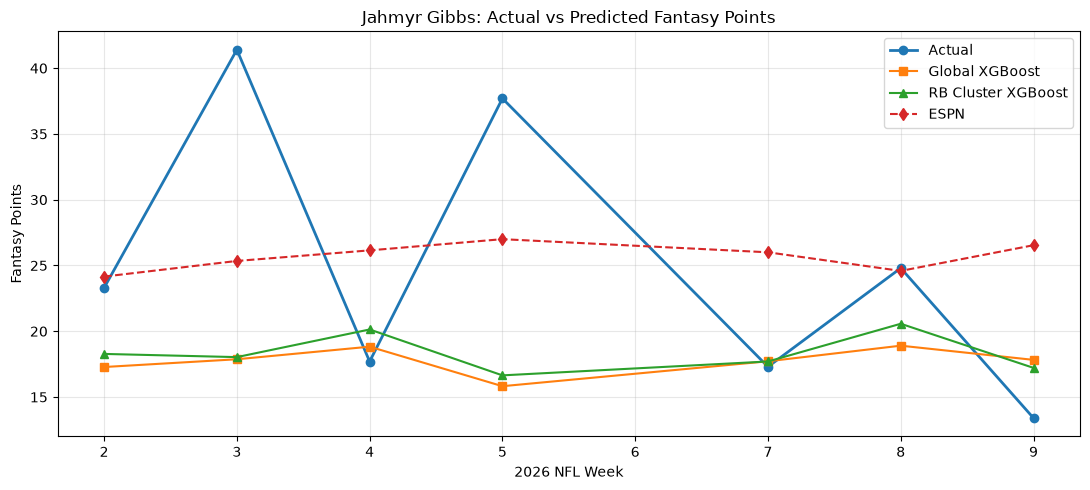

In [6]:
# Block 6: Compare saved models for an individual player

player_name = "Jahmyr Gibbs"

# 1. Find the player's completed 2026 games
rb_player = rb_df[
    (rb_df["season"] == 2026) &
    (rb_df["player"].str.lower() == player_name.lower()) &
    (rb_df["target_next_week_fantasy"].notna())
].copy()

if rb_player.empty:
    print("No completed predictions found for this player.")

else:
    # 2. Select the features required by Tristan's RB model
    X_player_rb = X_rb.loc[rb_player.index].copy()

    # FIX: Remove unused category labels
    # This prevents unrelated players, such as A.J. Brown,
    # from appearing in the categorical vocabulary.
    for col in X_player_rb.select_dtypes(
        include="category"
    ).columns:

        X_player_rb[col] = (
            X_player_rb[col].cat.remove_unused_categories()
        )

    # 3. Predict using SAVED RB model
    rb_predictions = rb_model.predict(X_player_rb)

    # 4. Create RB prediction results
    rb_results = pd.DataFrame({
        "Predicted_Week": rb_player["next_week_target_week"].values,
        "RB_Cluster": rb_predictions
    })

    # 5. Merge with Global XGBoost results from Block 4
    comparison = player_results.merge(
        rb_results,
        on="Predicted_Week",
        how="inner",
        validate="one_to_one"
    )

    # Verify that the same games are being compared
    assert len(comparison) == len(player_results), (
        "Some player-games did not match between models."
    )

    # 6. Calculate absolute errors
    comparison["Global_Error"] = (
        comparison["Actual"] -
        comparison["Global_XGBoost"]
    ).abs()

    comparison["RB_Error"] = (
        comparison["Actual"] -
        comparison["RB_Cluster"]
    ).abs()

    comparison["ESPN_Error"] = (
        comparison["Actual"] -
        comparison["ESPN"]
    ).abs()

    # 7. Display player-level predictions
    print(f"Player: {player_name}")
    print(f"Games compared: {len(comparison)}")

    display(
        comparison[
            [
                "Predicted_Week",
                "Actual",
                "Global_XGBoost",
                "RB_Cluster",
                "ESPN",
                "Global_Error",
                "RB_Error",
                "ESPN_Error"
            ]
        ].sort_values("Predicted_Week").round(2)
    )

    # 8. Calculate MAE for each approach
    results = pd.DataFrame({
        "Model": [
            "Global XGBoost",
            "RB Cluster XGBoost",
            "ESPN"
        ],
        "MAE": [
            comparison["Global_Error"].mean(),
            comparison["RB_Error"].mean(),
            comparison["ESPN_Error"].mean()
        ]
    }).sort_values("MAE")

    print("\nModel Comparison (Lower MAE is Better)")
    display(results.round(3))

    # 9. Visualize actual vs predicted fantasy points
    plt.figure(figsize=(11, 5))

    comparison = comparison.sort_values("Predicted_Week")

    plt.plot(
        comparison["Predicted_Week"],
        comparison["Actual"],
        marker="o",
        linewidth=2,
        label="Actual"
    )

    plt.plot(
        comparison["Predicted_Week"],
        comparison["Global_XGBoost"],
        marker="s",
        label="Global XGBoost"
    )

    plt.plot(
        comparison["Predicted_Week"],
        comparison["RB_Cluster"],
        marker="^",
        label="RB Cluster XGBoost"
    )

    plt.plot(
        comparison["Predicted_Week"],
        comparison["ESPN"],
        marker="d",
        linestyle="--",
        label="ESPN"
    )

    plt.title(f"{player_name}: Actual vs Predicted Fantasy Points")
    plt.xlabel("2026 NFL Week")
    plt.ylabel("Fantasy Points")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

> **Note:** the numbers below come from the earlier clustered models (different feature set). Update them after re-running `XGBoost_cluster.ipynb` and this notebook.

### Interpretation: Global vs. Clustered Model

I compared saved Global XGBoost and RB Cluster models against ESPN projections for Jahmyr Gibbs during seven games in the 2026 season.

ESPN achieved the lowest MAE (8.302), followed by Global XGBoost (8.814) and RB Cluster XGBoost (9.385).

Although the RB model was trained only on running backs, it did not outperform the global model for this player. Both models also struggled to predict unusually high-scoring games, particularly Weeks 3 and 5.

However, this analysis includes only one player and seven games, so the results are not sufficient to conclude that the global model is generally better than the clustered model.

## 7. QB + TE and WR + K Cluster Models

The inputs for the QB + TE and WR + K models were prepared together with the RB model in the cluster preparation block above. All three cluster models use the same 97 features as the Global XGBoost model, so their inputs are the matching rows of `X_global`.

In [7]:
# Block 7: Check the remaining saved cluster model inputs
for model_name in ["QB + TE Cluster", "WR + K Cluster"]:
    X_cluster = cluster_inputs[model_name]

    assert list(X_cluster.columns) == model_features[model_name]
    assert "target_next_week_fantasy" not in X_cluster.columns

    print(f"\n{model_name}")
    print("-" * 45)
    print("Input shape:", X_cluster.shape)
    print("Positions:", cluster_positions[model_name])
    print("Status: Ready!")

print("\nBoth remaining cluster models are prepared.")


QB + TE Cluster
---------------------------------------------
Input shape: (6318, 97)
Positions: ['QB', 'TE']
Status: Ready!

WR + K Cluster
---------------------------------------------
Input shape: (8556, 97)
Positions: ['WR', 'K']
Status: Ready!

Both remaining cluster models are prepared.



## 8. Interactive Player-Level Model Comparison

I created a reusable function to compare predictions for individual players across the 2026 season.

Based on the player's position, the function automatically selects the appropriate saved clustered XGBoost model and compares it against the saved Global XGBoost model and ESPN projections.

The function calculates Mean Absolute Error (MAE) for each approach and visualizes predicted versus actual fantasy points.

All predictions use Tristan's previously trained models without retraining.



Player: Patrick Mahomes
Position: QB
Cluster model: QB + TE Cluster
Games evaluated: 7


,Week,Actual,Global_XGBoost,Cluster_XGBoost,ESPN
0,2.0,28.98,17.500000,17.990000,18.22
1,3.0,15.94,17.110001,17.580000,19.63
2,4.0,17.00,17.400000,17.559999,18.69
3,6.0,10.48,16.389999,16.940001,18.77
4,7.0,6.00,16.820000,17.280001,15.61
5,8.0,25.44,14.760000,15.170000,14.23
6,9.0,16.48,16.559999,17.500000,18.17



Model Performance (Lower MAE is Better)


,Model,MAE
0,Global XGBoost,5.791
1,QB + TE Cluster,6.031
2,ESPN,6.706


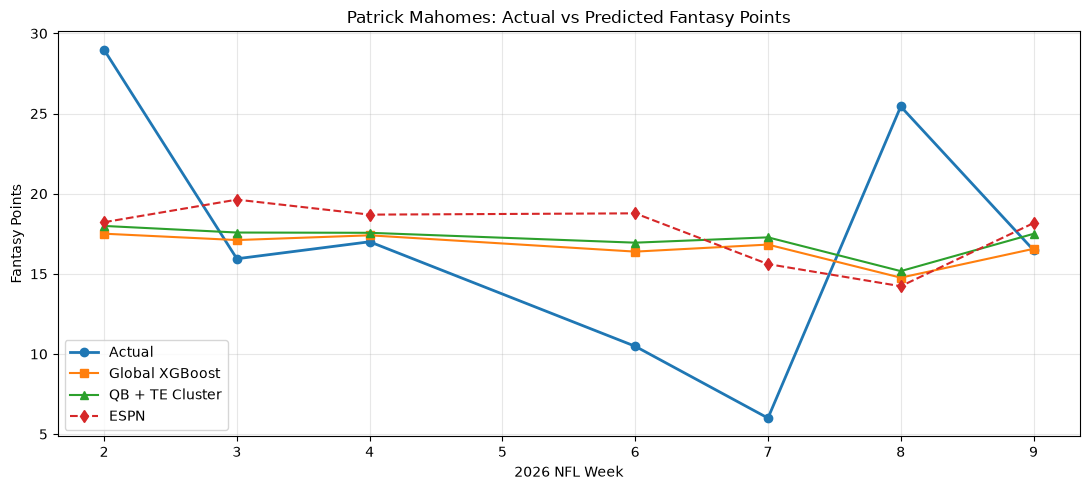

In [8]:
def compare_player(player_name):

    # Find matching players in the global dataset
    matches = global_df[
        (global_df["season"] == 2026) &
        (global_df["player"].astype(str).str.contains(
            player_name, case=False, regex=False, na=False
        ))
    ].copy()

    names = matches["player"].astype(str).unique()

    if len(names) == 0:
        print("Player not found.")
        return

    if len(names) > 1:
        print("Multiple matches:", list(names))
        print("Please enter a more specific name.")
        return

    player = names[0]
    position = str(matches["position"].iloc[0])

    # Automatically choose the saved cluster model
    cluster_name = next(
        (name for name, positions in cluster_positions.items()
         if position in positions),
        None
    )

    if cluster_name is None:
        print("Unsupported position:", position)
        return

    source_df = cluster_datasets[cluster_name]
    source_X = cluster_inputs[cluster_name]

    # Select completed next-game observations
    global_rows = matches[
        matches["target_next_week_fantasy"].notna()
    ].copy()

    cluster_rows = source_df[
        (source_df["season"] == 2026) &
        (source_df["player"].astype(str) == player) &
        (source_df["target_next_week_fantasy"].notna())
    ].copy()

    if global_rows.empty or cluster_rows.empty:
        print("No completed games available.")
        return

    # Predict with the saved Global XGBoost model
    X_g = X_global.loc[global_rows.index].copy()

    # Remove unused category labels
    for col in X_g.select_dtypes(include="category").columns:
        X_g[col] = X_g[col].cat.remove_unused_categories()

    global_predictions = loaded_models[
        "Global XGBoost"
    ].predict(X_g)

    # Predict with the appropriate saved Cluster model
    X_c = source_X.loc[cluster_rows.index].copy()

    for col in X_c.select_dtypes(include="category").columns:
        X_c[col] = X_c[col].cat.remove_unused_categories()

    cluster_predictions = loaded_models[
        cluster_name
    ].predict(X_c)

    # Global results
    global_results = pd.DataFrame({
        "player_id": global_rows["player_id"].values,
        "Week": global_rows["next_week_target_week"].values,
        "Actual": global_rows[
            "target_next_week_fantasy"
        ].values,
        "Global_XGBoost": global_predictions,
        "ESPN": global_rows["next_week_projected"].values
    })

    # Cluster results
    cluster_results = pd.DataFrame({
        "player_id": cluster_rows["player_id"].values,
        "Week": cluster_rows["next_week_target_week"].values,
        "Cluster_XGBoost": cluster_predictions
    })

    # Compare only matching player-games
    comparison = global_results.merge(
        cluster_results,
        on=["player_id", "Week"],
        how="inner",
        validate="one_to_one"
    ).sort_values("Week")

    if comparison.empty:
        print("No matching games between models.")
        return

    # Calculate absolute errors
    comparison["Global_Error"] = abs(
        comparison["Actual"] - comparison["Global_XGBoost"]
    )

    comparison["Cluster_Error"] = abs(
        comparison["Actual"] - comparison["Cluster_XGBoost"]
    )

    comparison["ESPN_Error"] = abs(
        comparison["Actual"] - comparison["ESPN"]
    )

    # Calculate MAE
    mae_table = pd.DataFrame({
        "Model": ["Global XGBoost", cluster_name, "ESPN"],
        "MAE": [
            comparison["Global_Error"].mean(),
            comparison["Cluster_Error"].mean(),
            comparison["ESPN_Error"].mean()
        ]
    }).sort_values("MAE")

    print(f"\nPlayer: {player}")
    print(f"Position: {position}")
    print(f"Cluster model: {cluster_name}")
    print(f"Games evaluated: {len(comparison)}")

    display(
        comparison[
            ["Week", "Actual", "Global_XGBoost",
             "Cluster_XGBoost", "ESPN"]
        ].round(2)
    )

    print("\nModel Performance (Lower MAE is Better)")
    display(mae_table.round(3))

    # Visualization
    plt.figure(figsize=(11, 5))

    plt.plot(
        comparison["Week"], comparison["Actual"],
        marker="o", linewidth=2, label="Actual"
    )

    plt.plot(
        comparison["Week"], comparison["Global_XGBoost"],
        marker="s", label="Global XGBoost"
    )

    plt.plot(
        comparison["Week"], comparison["Cluster_XGBoost"],
        marker="^", label=cluster_name
    )

    plt.plot(
        comparison["Week"], comparison["ESPN"],
        marker="d", linestyle="--", label="ESPN"
    )

    plt.title(f"{player}: Actual vs Predicted Fantasy Points")
    plt.xlabel("2026 NFL Week")
    plt.ylabel("Fantasy Points")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return comparison, mae_table


# Try a quarterback first
comparison_result, model_mae = compare_player("Patrick Mahomes")

> **Note:** the numbers below come from the earlier clustered models (different feature set). Update them after re-running `XGBoost_cluster.ipynb` and this notebook.
### Interpretation: Patrick Mahomes (QB)

I tested saved Global XGBoost and QB + TE Cluster models using Patrick Mahomes's available 2026 games.

Across seven games, Global XGBoost achieved the lowest MAE (5.964), followed by QB + TE Cluster (6.147) and ESPN (6.706).

Both XGBoost models performed better than ESPN for this player, although the difference between the two XGBoost models was relatively small.

The visualization suggests that both models tend to predict scores within a relatively narrow range, making it difficult to capture unusually high or low performances.

These results are specific to Patrick Mahomes and should not be generalized to all quarterbacks.


## 9. Validating Predictions Across Player Positions

After successfully comparing predictions for a running back (Jahmyr Gibbs) and quarterback (Patrick Mahomes), I will test the remaining positions: wide receiver (WR), tight end (TE), and kicker (K).

The purpose is to verify that the reusable `compare_player()` function correctly selects the corresponding saved XGBoost cluster model for each position.

This also allows me to examine whether the global or position-specific model performs better for different types of players.

All evaluations use previously trained models and available 2026 game results.



TESTING PLAYER: Justin Jefferson

Player: Justin Jefferson
Position: WR
Cluster model: WR + K Cluster
Games evaluated: 6


,Week,Actual,Global_XGBoost,Cluster_XGBoost,ESPN
0,2.0,8.5,13.72,11.940000,18.36
1,3.0,5.2,15.58,13.680000,18.26
2,5.0,18.8,15.31,14.790000,18.88
3,7.0,8.4,15.94,16.530001,18.51
4,8.0,14.3,13.91,13.810000,17.88
5,9.0,8.8,14.93,15.420000,18.31



Model Performance (Lower MAE is Better)


,Model,MAE
1,WR + K Cluster,5.194
0,Global XGBoost,5.523
2,ESPN,7.701


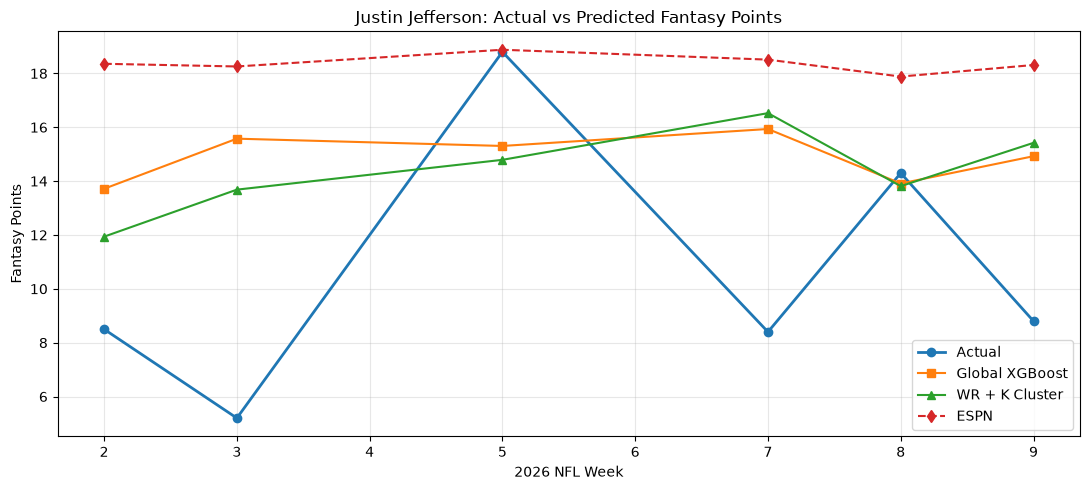


TESTING PLAYER: Travis Kelce

Player: Travis Kelce
Position: TE
Cluster model: QB + TE Cluster
Games evaluated: 7


,Week,Actual,Global_XGBoost,Cluster_XGBoost,ESPN
0,2.0,25.1,11.58,12.60,10.55
1,3.0,13.9,13.85,13.79,12.68
2,4.0,3.5,13.97,13.81,11.79
3,6.0,9.3,11.40,10.64,11.44
4,7.0,8.4,12.34,12.92,10.08
5,8.0,11.7,12.17,12.99,9.30
6,9.0,17.3,12.05,12.47,10.57



Model Performance (Lower MAE is Better)


,Model,MAE
1,QB + TE Cluster,4.985
0,Global XGBoost,5.115
2,ESPN,5.290


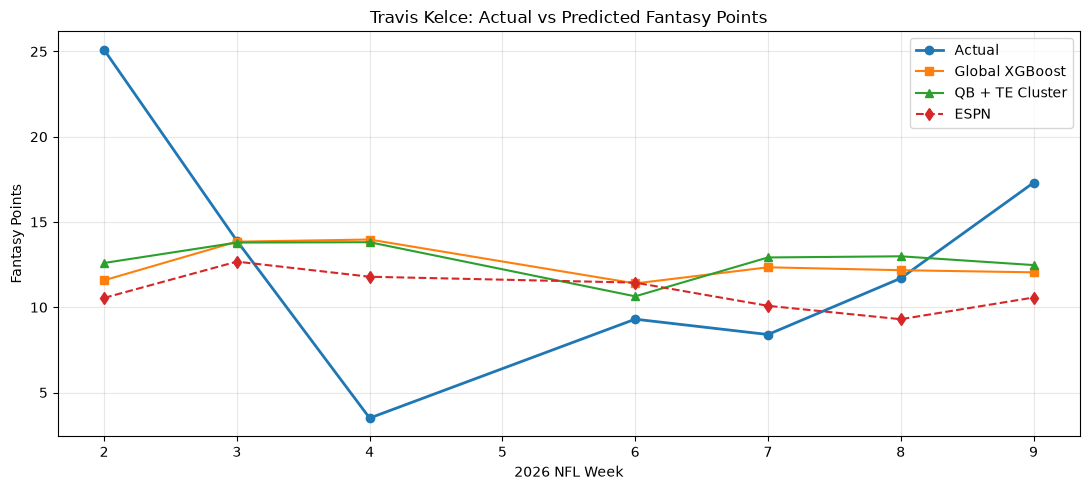


TESTING PLAYER: Brandon Aubrey

Player: Brandon Aubrey
Position: K
Cluster model: WR + K Cluster
Games evaluated: 8


,Week,Actual,Global_XGBoost,Cluster_XGBoost,ESPN
0,2.0,17.0,6.43,10.14,10.60
1,3.0,10.0,9.06,8.89,9.72
2,4.0,10.0,8.55,7.77,9.55
3,5.0,5.0,10.20,10.84,10.80
4,6.0,1.0,8.10,7.50,10.21
5,7.0,14.0,7.99,7.65,8.15
6,8.0,12.0,9.22,9.23,10.00
7,9.0,9.0,8.89,8.57,10.56



Model Performance (Lower MAE is Better)


,Model,MAE
2,ESPN,3.944
1,WR + K Cluster,4.010
0,Global XGBoost,4.270


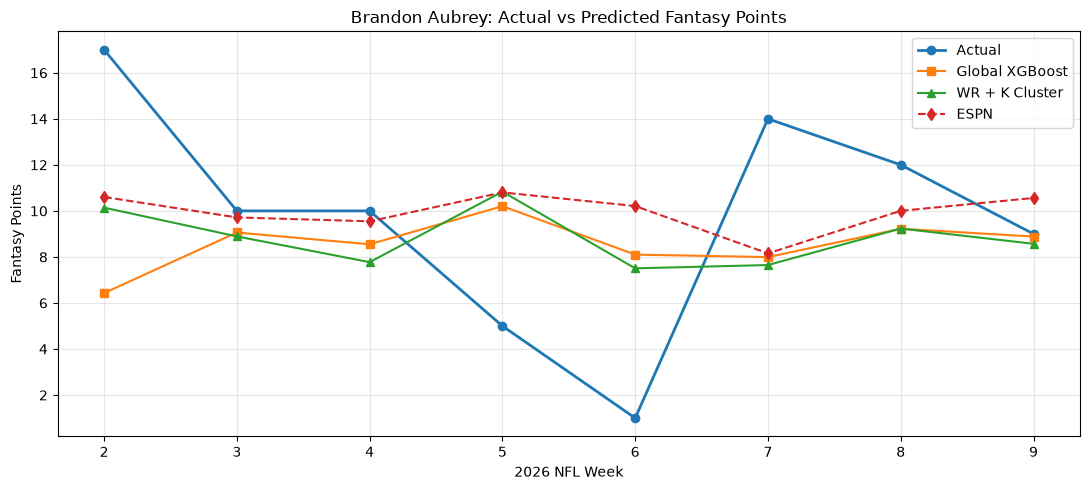

In [9]:

# Block 9: Test the remaining three positions

test_players = [
    "Justin Jefferson",  # WR
    "Travis Kelce",      # TE
    "Brandon Aubrey"     # K
]

for player in test_players:
    print("\n" + "=" * 60)
    print(f"TESTING PLAYER: {player}")
    print("=" * 60)

    try:
        compare_player(player)

    except Exception as e:
        print(f"Could not evaluate {player}")
        print("Reason:", str(e).split("Stack trace:")[0])



## 10. Preparing a Fair 2026 Test-Set Comparison

After testing individual players across all five positions, I will evaluate the saved XGBoost models across the full 2026 test dataset.

To ensure a fair comparison, I will match observations using player ID and the week being predicted.

Only observations with available actual fantasy points and ESPN projections will be included. This ensures Global XGBoost, the position-specific Cluster models, and ESPN are evaluated on the same player-games.




In [10]:
# Block 10: Match eligible 2026 player-games across models

# Combine the three position-specific cluster datasets
cluster_parts = []

for model_name, data in cluster_datasets.items():

    part = data[
        (data["season"] == 2026) &
        (data["target_next_week_fantasy"].notna())
    ][[
        "player_id",
        "player",
        "position",
        "next_week_target_week",
        "target_next_week_fantasy"
    ]].copy()

    part["Cluster_Model"] = model_name

    cluster_parts.append(part)

cluster_test = pd.concat(
    cluster_parts,
    ignore_index=True
)

cluster_test = cluster_test.rename(columns={
    "next_week_target_week": "Week",
    "target_next_week_fantasy": "Cluster_Actual"
})

# Prepare the Global model's eligible 2026 games
global_test = global_df[
    (global_df["season"] == 2026) &
    (global_df["target_next_week_fantasy"].notna()) &
    (global_df["next_week_projected"].notna())
][[
    "player_id",
    "player",
    "position",
    "next_week_target_week",
    "target_next_week_fantasy",
    "next_week_projected"
]].copy()

global_test = global_test.rename(columns={
    "next_week_target_week": "Week",
    "target_next_week_fantasy": "Actual",
    "next_week_projected": "ESPN"
})

# Keep only the player-games present in both datasets
test_2026 = global_test.merge(
    cluster_test[
        ["player_id", "Week", "Cluster_Actual", "Cluster_Model"]
    ],
    on=["player_id", "Week"],
    how="inner",
    validate="one_to_one"
)

# Check that both pipelines agree on actual scores
assert np.allclose(
    test_2026["Actual"],
    test_2026["Cluster_Actual"],
    equal_nan=True
), "Actual fantasy scores differ between pipelines."

# Check for duplicate player-games
assert not test_2026.duplicated(
    ["player_id", "Week"]
).any(), "Duplicate player-games found."

# Remove the duplicate target column
test_2026 = test_2026.drop(columns="Cluster_Actual")

print("2026 TEST DATASET")
print("-" * 45)
print("Matched player-games:", len(test_2026))
print("Unique players:", test_2026["player_id"].nunique())
print("Weeks:", sorted(test_2026["Week"].unique()))

print("\nObservations by position:")
display(
    test_2026["position"]
    .value_counts()
    .rename_axis("Position")
    .reset_index(name="Games")
)

print("\nObservations by cluster:")
display(
    test_2026["Cluster_Model"]
    .value_counts()
    .rename_axis("Cluster")
    .reset_index(name="Games")
)

print("\nSample matched observations:")
display(test_2026.head(10))

2026 TEST DATASET
---------------------------------------------
Matched player-games: 3163
Unique players: 562
Weeks: [np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0)]

Observations by position:


,Position,Games
0,WR,1151
1,TE,750
2,RB,740
3,QB,286
4,K,236



Observations by cluster:


,Cluster,Games
0,WR + K Cluster,1387
1,QB + TE Cluster,1036
2,RB Cluster,740



Sample matched observations:


,player_id,player,position,Week,Actual,ESPN,Cluster_Model
0,8439,Aaron Rodgers,QB,2.0,3.98,12.697518,QB + TE Cluster
1,8439,Aaron Rodgers,QB,3.0,22.68,14.427139,QB + TE Cluster
2,8439,Aaron Rodgers,QB,4.0,21.96,13.780833,QB + TE Cluster
3,8439,Aaron Rodgers,QB,5.0,22.00,15.900644,QB + TE Cluster
4,8439,Aaron Rodgers,QB,6.0,16.02,14.872793,QB + TE Cluster
5,8439,Aaron Rodgers,QB,7.0,13.08,19.465029,QB + TE Cluster
6,8439,Aaron Rodgers,QB,8.0,4.88,15.084118,QB + TE Cluster
7,10621,Nick Folk,K,2.0,3.00,8.318715,WR + K Cluster
8,10621,Nick Folk,K,3.0,10.00,7.874953,WR + K Cluster
9,10621,Nick Folk,K,4.0,9.00,8.240817,WR + K Cluster



## 11. Generate Predictions Across the 2026 Test Dataset

I will now use four saved XGBoost models to generate predictions for the matched 2026 player-games.

Each player receives a prediction from the Global XGBoost model and the appropriate position-specific Cluster model.

Some predictions may fail if the saved model encounters categories that were not present during training. I will record these cases and keep only player-games where both models successfully generate predictions.

This ensures that the subsequent MAE, RMSE, and R² comparisons use the same observations for Global XGBoost, Cluster XGBoost, and ESPN.


In [11]:
# Block 11: Generate 2026 test predictions without retraining

import numpy as np
import pandas as pd

keys = ["player_id", "Week"]

def predict_test_rows(model_name, source_df, X_source, week_col):
    """
    Predict matched 2026 games using a saved XGBoost model.
    If a full-batch prediction fails because of an unknown
    category, retry by player and report skipped records.
    """

    # Link the original feature rows to our matched test games
    lookup = source_df.reset_index().rename(columns={
        "index": "source_row",
        week_col: "Week"
    })

    lookup = lookup[
        (lookup["season"] == 2026) &
        (lookup["Week"].notna())
    ]

    matched = test_2026[keys].merge(
        lookup[keys + ["source_row"]],
        on=keys,
        how="inner",
        validate="one_to_one"
    )

    model = loaded_models[model_name]
    outputs = []
    failed = []

    def make_predictions(rows):
        X = X_source.loc[rows["source_row"]].copy()

        # Remove unused categories before XGBoost inference
        for col in X.select_dtypes(include="category").columns:
            X[col] = X[col].cat.remove_unused_categories()

        return model.predict(X)

    # First try predicting all matched records together
    try:
        predictions = make_predictions(matched)

        result = matched[keys].copy()
        result["Prediction"] = predictions
        outputs.append(result)

    except Exception as batch_error:
        print(f"{model_name}: Batch prediction failed.")
        print("Retrying player by player.")

        # Isolate players with unsupported categories
        for player_id, rows in matched.groupby("player_id"):

            try:
                predictions = make_predictions(rows)

                result = rows[keys].copy()
                result["Prediction"] = predictions
                outputs.append(result)

            except Exception as e:
                failed.append({
                    "Model": model_name,
                    "player_id": player_id,
                    "Games": len(rows),
                    "Reason": str(e).split("Stack trace:")[0]
                })

    if outputs:
        predictions_df = pd.concat(outputs, ignore_index=True)
    else:
        predictions_df = pd.DataFrame(
            columns=keys + ["Prediction"]
        )

    print(f"\n{model_name}")
    print("Matched games:", len(matched))
    print("Successful predictions:", len(predictions_df))
    print("Skipped games:", len(matched) - len(predictions_df))

    return predictions_df, failed


# 1. Global model predictions
global_predictions, global_failed = predict_test_rows(
    "Global XGBoost",
    global_df,
    X_global,
    "next_week_target_week"
)

global_predictions = global_predictions.rename(
    columns={"Prediction": "Global_XGBoost"}
)


# 2. Predictions from all three cluster models
cluster_predictions_list = []
all_failed = global_failed.copy()

for name in cluster_positions:

    predictions, failures = predict_test_rows(
        name, cluster_datasets[name], cluster_inputs[name],
        "next_week_target_week"
    )

    predictions["Cluster_Model"] = name
    cluster_predictions_list.append(predictions)
    all_failed.extend(failures)

cluster_predictions = pd.concat(
    cluster_predictions_list,
    ignore_index=True
).rename(columns={"Prediction": "Cluster_XGBoost"})


# 3. Match successful predictions from both approaches
test_predictions = test_2026.merge(
    global_predictions,
    on=keys,
    how="inner",
    validate="one_to_one"
).merge(
    cluster_predictions[keys + ["Cluster_XGBoost"]],
    on=keys,
    how="inner",
    validate="one_to_one"
)

# Check that all values used for evaluation are finite
score_cols = [
    "Actual", "ESPN",
    "Global_XGBoost", "Cluster_XGBoost"
]

test_predictions = test_predictions[
    np.isfinite(test_predictions[score_cols]).all(axis=1)
].copy()


# 4. Report how many observations are usable
print("\n" + "=" * 50)
print("FINAL MATCHED PREDICTION DATASET")
print("=" * 50)

print("Original matched games:", len(test_2026))
print("Games with both predictions:", len(test_predictions))
print("Games excluded:",
      len(test_2026) - len(test_predictions))

print("\nGames by position:")
display(
    test_predictions["position"]
    .value_counts()
    .rename_axis("Position")
    .reset_index(name="Games")
)

print("\nSample predictions:")
display(
    test_predictions[
        ["player", "position", "Week", "Actual",
         "Global_XGBoost", "Cluster_XGBoost", "ESPN"]
    ].head(10).round(2)
)

# 5. Keep a record of categorical prediction failures
failed_predictions = pd.DataFrame(all_failed)

if not failed_predictions.empty:
    print("\nPlayers skipped due to prediction errors:")
    display(failed_predictions[
        ["Model", "player_id", "Games", "Reason"]
    ].head(10))
else:
    print("\nNo categorical prediction failures recorded.")


Global XGBoost
Matched games: 3163
Successful predictions: 3163
Skipped games: 0


/tmp/ipykernel_10802/156135539.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lookup = source_df.reset_index().rename(columns={
/tmp/ipykernel_10802/156135539.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lookup = source_df.reset_index().rename(columns={
/tmp/ipykernel_10802/156135539.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de


RB Cluster
Matched games: 740
Successful predictions: 740
Skipped games: 0

QB + TE Cluster
Matched games: 1036
Successful predictions: 1036
Skipped games: 0

WR + K Cluster
Matched games: 1387
Successful predictions: 1387
Skipped games: 0

FINAL MATCHED PREDICTION DATASET
Original matched games: 3163
Games with both predictions: 3163
Games excluded: 0

Games by position:


/tmp/ipykernel_10802/156135539.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lookup = source_df.reset_index().rename(columns={


,Position,Games
0,WR,1151
1,TE,750
2,RB,740
3,QB,286
4,K,236



Sample predictions:


,player,position,Week,Actual,Global_XGBoost,Cluster_XGBoost,ESPN
0,Aaron Rodgers,QB,2.0,3.98,14.06,15.02,12.70
1,Aaron Rodgers,QB,3.0,22.68,13.80,13.66,14.43
2,Aaron Rodgers,QB,4.0,21.96,12.40,12.53,13.78
3,Aaron Rodgers,QB,5.0,22.00,13.89,13.96,15.90
4,Aaron Rodgers,QB,6.0,16.02,14.56,16.60,14.87
5,Aaron Rodgers,QB,7.0,13.08,14.00,12.70,19.47
6,Aaron Rodgers,QB,8.0,4.88,12.86,13.37,15.08
7,Nick Folk,K,2.0,3.00,8.14,8.53,8.32
8,Nick Folk,K,3.0,10.00,7.71,6.77,7.87
9,Nick Folk,K,4.0,9.00,8.26,8.30,8.24



No categorical prediction failures recorded.


> **Note:** the numbers below come from the earlier clustered models (different feature set). Update them after re-running `XGBoost_cluster.ipynb` and this notebook.
## 12. Overall Model Performance on the 2026 Test Set

I evaluated saved Global XGBoost model, the three position-specific Cluster models, and ESPN projections on the same 3,163 player-game observations from 2026.

The three clustered models are combined into one set of predictions based on each player's position.

I use Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² to compare prediction accuracy.

This evaluation uses previously trained models without retraining.

OVERALL 2026 TEST PERFORMANCE


,Model,Games,MAE,RMSE,R2
0,ESPN,3163,3.868,5.504,0.496
1,Global XGBoost,3163,4.410,5.964,0.408
2,Combined Cluster XGBoost,3163,4.572,6.061,0.389



GLOBAL VS CLUSTER COMPARISON
--------------------------------------------------
Global XGBoost MAE: 4.410
Combined Cluster MAE: 4.572
MAE difference (Cluster - Global): +0.162
Result: Global XGBoost has lower overall MAE.


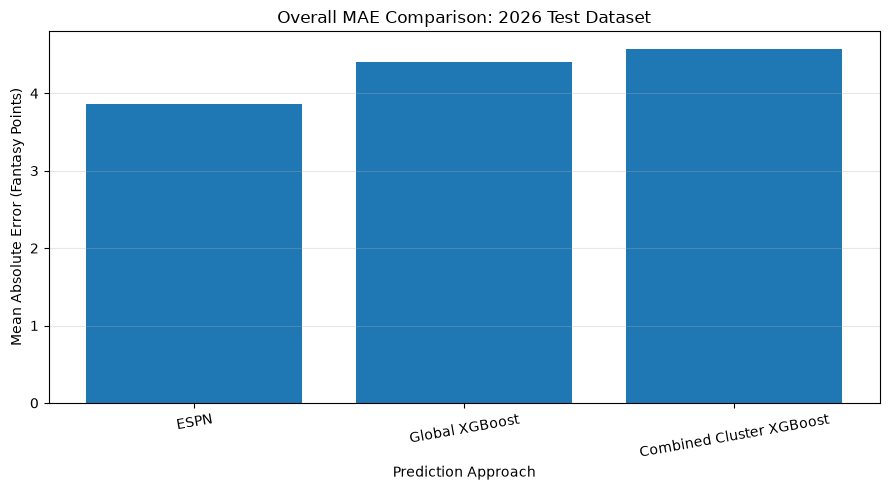

In [12]:

# Block 12: Compare overall performance on matched 2026 games

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Actual fantasy scores
y_true = test_predictions["Actual"]

# Predictions from Tristan's saved models and ESPN
model_columns = {
    "Global XGBoost": "Global_XGBoost",
    "Combined Cluster XGBoost": "Cluster_XGBoost",
    "ESPN": "ESPN"
}

metrics = []

for model_name, column in model_columns.items():

    y_pred = test_predictions[column]

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    metrics.append({
        "Model": model_name,
        "Games": len(y_true),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Overall results
overall_results = pd.DataFrame(metrics)

overall_results = overall_results.sort_values(
    "MAE"
).reset_index(drop=True)

print("OVERALL 2026 TEST PERFORMANCE")
print("=" * 50)

display(overall_results.round(3))

# Calculate how clustering compares with the global model
global_mae = overall_results.loc[
    overall_results["Model"] == "Global XGBoost",
    "MAE"
].iloc[0]

cluster_mae = overall_results.loc[
    overall_results["Model"] == "Combined Cluster XGBoost",
    "MAE"
].iloc[0]

difference = cluster_mae - global_mae

print("\nGLOBAL VS CLUSTER COMPARISON")
print("-" * 50)

print(f"Global XGBoost MAE: {global_mae:.3f}")
print(f"Combined Cluster MAE: {cluster_mae:.3f}")
print(f"MAE difference (Cluster - Global): {difference:+.3f}")

if difference < 0:
    print("Result: Clustering has lower overall MAE.")
elif difference > 0:
    print("Result: Global XGBoost has lower overall MAE.")
else:
    print("Result: Both approaches have identical overall MAE.")

# Visualize the three MAE values
plt.figure(figsize=(9, 5))

plt.bar(
    overall_results["Model"],
    overall_results["MAE"]
)

plt.title("Overall MAE Comparison: 2026 Test Dataset")
plt.ylabel("Mean Absolute Error (Fantasy Points)")
plt.xlabel("Prediction Approach")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
